# Étape 3 – Analyse exploratoire du corpus

**Questions** : comment le volume évolue-t-il (jour, semaine, mois) ? Quels médias, rubriques et territoires dominent ? Les titres sont-ils assez longs pour une analyse textuelle ?
Quelles données faut-il écarter ou corriger (agenda répétitif, jours creux) avant de modéliser ?

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)
MEDIA_ORDER = ["Le Progrès", "Lyon Capitale", "LyonMag", "BFM Lyon"]
MEDIA_COLORS = dict(zip(MEDIA_ORDER, sns.color_palette("deep")[:4]))

corpus = pd.read_parquet(ROOT / "data" / "processed" / "corpus.parquet")
funnel = pd.Series({
    "Articles collectés (corpus)": len(corpus),
    "… dans le périmètre lyonnais (in_scope)": corpus["in_scope"].sum(),
    "… hors agenda et contenus sponsorisés (in_analysis)": corpus["in_analysis"].sum(),
})
df = corpus[corpus["in_analysis"]].copy()
display(funnel.to_frame("articles").assign(part=lambda d: (100 * d["articles"] / len(corpus)).round(1)))
print(df["media_name"].value_counts().to_string())

,articles,part
Articles collectés (corpus),13998,100.0
… dans le périmètre lyonnais (in_scope),5026,35.9
… hors agenda et contenus sponsorisés (in_analysis),4936,35.3


media_name
Le Progrès       2171
Lyon Capitale    1855
LyonMag           832
BFM Lyon           78


## 1. Agenda et contenus sponsorisés : à écarter
La rubrique **pour-sortir** du Progrès est un agenda de fiches en gabarit (« Concert du chœur Crescendo : Concert Chorale a Villeurbanne ») : elle répète le même squelette de mots et formerait un « thème » artificiel.
Les rubriques `paroles-de-partenaires` et `comparateur-telecom` sont du contenu commercial. Ces articles sont **conservés dans le corpus** (colonne `content_type`) mais exclus de l'analyse (`in_analysis`).

In [2]:
scope = corpus[corpus["in_scope"]]
print(scope["content_type"].value_counts().to_string())
print("\nExemples d'agenda :"); print(scope[scope.content_type == "agenda"]["title"].sample(5, random_state=0).to_string(index=False))
print("\nExemples sponsorisés :"); print(scope[scope.content_type == "sponsored"]["title"].head(4).to_string(index=False))
print(f"\nTitres identiques dans le même média, après exclusion : {df['dup_title'].sum()} articles ({df['dup_title'].mean():.1%})")
display(df[df.dup_title].groupby(["media_name", "title"]).size().sort_values(ascending=False).head(6).to_frame("occurrences"))

content_type
editorial    4936
agenda         84
sponsored       6

Exemples d'agenda :
                     Spectacle du collectif Yggdrasil : Spectacle a Villeurbanne
Spectacle de la compagnie "Liv collective" : Theatre contemporain a Villeurbanne
                             Concert de Joube : Musique   Electro a Villeurbanne
            Spectacle du Ballet de Thailande : Spectacle de danse a Villeurbanne
    Soiree de l association "La campanule" : Bal, soiree dansante a Villeurbanne

Exemples sponsorisés :
                                                   Gastronomie. Saveurs et savoir-faire dans le Rhône et l'Ain
                                                Automobile. Omoda Jaecoo et Chery s'installent au Nord de Lyon
                       Sorties. Boire un verre à Lyon : les quartiers qui montent, du Vieux Lyon aux Brotteaux
Études/Formation. Salon Studyrama des Études Supérieures : le grand rendez-vous de l'orientation revient le...

Titres identiques dans le même média, 

occurrences
media_name    title                                                                                                                      
Lyon Capitale Le récap' des temps forts de la semaine                                                                                   7
LyonMag       Mobilisation à Lyon : la façade d'un lycée incendiée, tirs de mortiers, collégien blessé… la matinée démarr...            3
              Pas de cours à l'université Lyon 2 ce lundi à cause des blocus, 27 établissements touchés dans le Rhône                   3
Lyon Capitale Deux boulangeries lyonnaises récompensées au concours de la meilleure baguette tradition du Rhône                         2
              Feux de forêts : sept départements d'Auvergne-Rhône-Alpes en vigilance                                                    2
              Gilles Vesco : "Le projet de Sarselli et Aulas, c'est une dystopie"                                                       2

## 2. Volume dans le temps

Articles/jour (analyse) : {'count': 91.0, 'mean': 54.2, 'std': 10.3, 'min': 32.0, '25%': 46.5, '50%': 54.0, '75%': 62.5, 'max': 75.0}


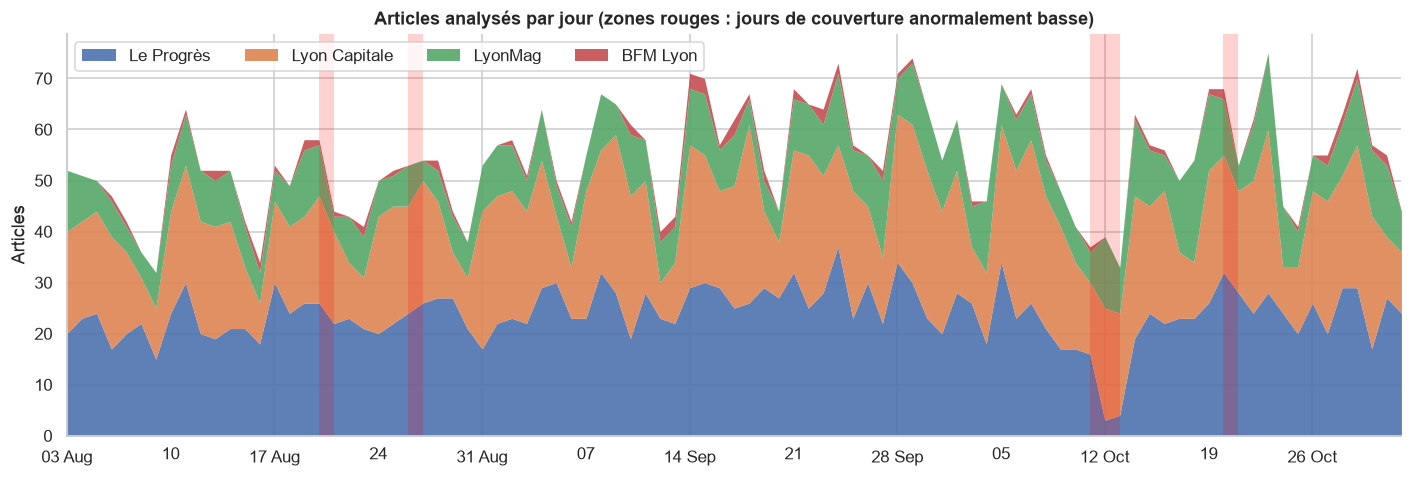

In [3]:
days = pd.date_range(df["date"].min(), df["date"].max())
daily = df.groupby(["date", "media_name"]).size().unstack(fill_value=0).reindex(days, fill_value=0)[MEDIA_ORDER]
print("Articles/jour (analyse) :", daily.sum(axis=1).describe().round(1).to_dict())

fig, ax = plt.subplots(figsize=(13, 4.5))
daily.plot.area(ax=ax, linewidth=0, alpha=0.9, color=[MEDIA_COLORS[m] for m in daily.columns])
for d in sorted(set(df.loc[df.low_coverage_day, "date"])):
    ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color="red", alpha=0.18, lw=0)
ax.set(title="Articles analysés par jour (zones rouges : jours de couverture anormalement basse)", ylabel="Articles", xlabel="")
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0, interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.legend(title="", ncol=4, loc="upper left")
plt.tight_layout(); fig.savefig(FIG / "03_volume_par_jour.png", bbox_inches="tight"); plt.show()

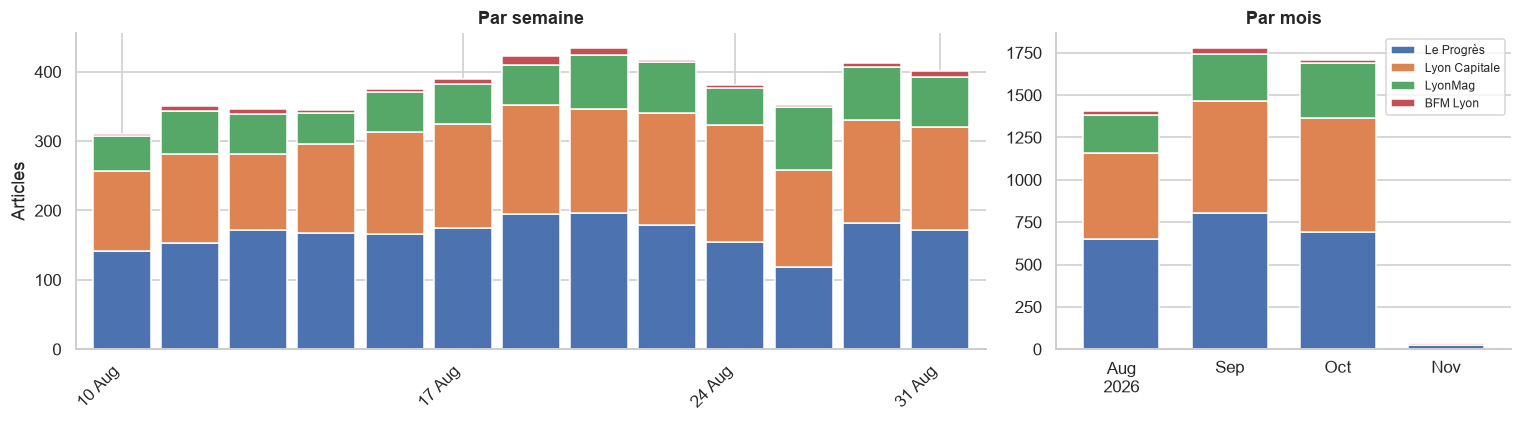

media_name,Le Progrès,Lyon Capitale,LyonMag,BFM Lyon,total,jours couverts,articles/jour
date,,,,,,,
2026-08,650,510,224,21,1405,29,48.4
2026-09,803,665,274,35,1777,30,59.2
2026-10,694,668,326,22,1710,31,55.2
2026-11,24,12,8,0,44,1,44.0


In [4]:
weekly = df.groupby(["week_start", "media_name"]).size().unstack(fill_value=0)[MEDIA_ORDER]
monthly = df.groupby([df["date"].dt.to_period("M"), "media_name"]).size().unstack(fill_value=0)[MEDIA_ORDER]
monthly["total"] = monthly.sum(axis=1)
monthly["jours couverts"] = df.groupby(df["date"].dt.to_period("M"))["date"].nunique()
monthly["articles/jour"] = (monthly["total"] / monthly["jours couverts"]).round(1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
weekly.plot.bar(stacked=True, ax=axes[0], width=0.85, color=[MEDIA_COLORS[m] for m in weekly.columns], legend=False)
axes[0].set(title="Par semaine", xlabel="", ylabel="Articles"); axes[0].set_xticklabels([d.strftime("%d %b") for d in weekly.index], rotation=45, ha="right")
monthly[MEDIA_ORDER].plot.bar(stacked=True, ax=axes[1], width=0.7, color=[MEDIA_COLORS[m] for m in MEDIA_ORDER])
axes[1].set(title="Par mois", xlabel="", ylabel=""); axes[1].set_xticklabels([str(p) for p in monthly.index], rotation=0); axes[1].legend(title="", fontsize=8)
plt.tight_layout(); fig.savefig(FIG / "03_volume_semaine_mois.png", bbox_inches="tight"); plt.show()
monthly

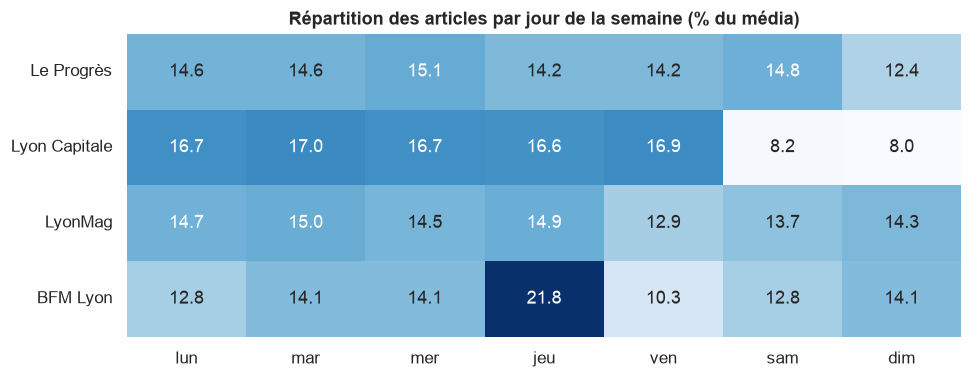

In [5]:
# Profil hebdomadaire : part des articles de chaque média publiée chaque jour de la semaine
dow = df.groupby(["media_name", "day_of_week"]).size().unstack(fill_value=0).reindex(MEDIA_ORDER)
dow_share = dow.div(dow.sum(axis=1), axis=0) * 100
dow_share.columns = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.heatmap(dow_share.round(1), annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax)
ax.set(title="Répartition des articles par jour de la semaine (% du média)", ylabel="", xlabel="")
plt.tight_layout(); fig.savefig(FIG / "03_jour_de_semaine.png", bbox_inches="tight"); plt.show()

## 3. Jours creux et composition par média

In [6]:
flag = corpus[corpus["low_coverage_day"]].groupby(["media_name", "date"]).size().rename("articles").reset_index()
display(flag)
mix = (weekly.div(weekly.sum(axis=1), axis=0) * 100).round(1)
print("Part de chaque média dans le périmètre, par semaine (%) :"); display(mix)
print(f"Part moyenne de Le Progrès : {mix['Le Progrès'].mean():.1f} % ; semaine du 12 octobre : {mix.loc[pd.Timestamp('2026-10-12'), 'Le Progrès']:.1f} %")

,media_name,date,articles
0,Le Progrès,2026-08-02,1
1,Le Progrès,2026-10-12,11
2,Le Progrès,2026-10-13,33
3,LyonMag,2026-08-21,3
4,LyonMag,2026-08-27,4
5,LyonMag,2026-10-21,5


Part de chaque média dans le périmètre, par semaine (%) :


media_name,Le Progrès,Lyon Capitale,LyonMag,BFM Lyon
week_start,,,,
2026-08-03,45.5,37.4,16.5,0.6
2026-08-10,43.6,36.5,17.7,2.3
2026-08-17,49.7,31.8,16.5,2.0
2026-08-24,48.4,37.4,13.0,1.2
2026-08-31,44.3,39.2,15.5,1.1
2026-09-07,45.0,38.3,15.2,1.5
2026-09-14,46.1,37.1,13.7,3.1
2026-09-21,45.4,34.6,17.7,2.3
2026-09-28,42.9,38.8,17.5,0.7


Part moyenne de Le Progrès : 44.0 % ; semaine du 12 octobre : 33.5 %


## 4. Rubriques et territoires

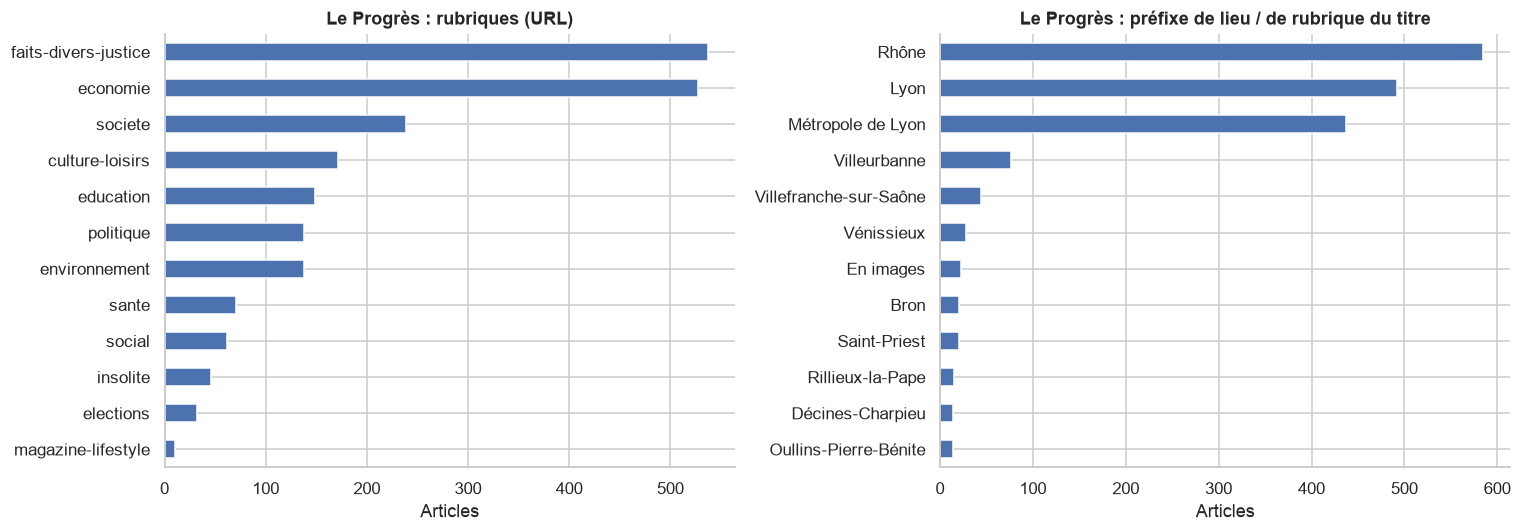

Lyon Capitale : {'actualite': 1657, 'culture': 87, 'regions': 50, 'logement-immobilier': 10}
LyonMag / BFM : pas de rubrique exploitable dans l'URL.


In [7]:
lp = df[df.media_name == "Le Progrès"]
sec = lp["section"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sec.head(12).iloc[::-1].plot.barh(ax=axes[0], color=MEDIA_COLORS["Le Progrès"]); axes[0].set(title="Le Progrès : rubriques (URL)", xlabel="Articles", ylabel="")
pl = lp["place_prefix"].value_counts().head(12)
pl.iloc[::-1].plot.barh(ax=axes[1], color=MEDIA_COLORS["Le Progrès"]); axes[1].set(title="Le Progrès : préfixe de lieu / de rubrique du titre", xlabel="Articles", ylabel="")
plt.tight_layout(); fig.savefig(FIG / "03_rubriques_progres.png", bbox_inches="tight"); plt.show()
print("Lyon Capitale :", df[df.media_name == "Lyon Capitale"]["section"].value_counts().head(4).to_dict())
print("LyonMag / BFM : pas de rubrique exploitable dans l'URL.")

## 5. Longueur des titres

n_words                   n_chars
                 mean   50%   min   max    mean
media_name                                     
Le Progrès       16.4  16.0   5.0  33.0    93.7
Lyon Capitale    13.1  13.0   2.0  27.0    78.8
LyonMag          14.8  15.0   2.0  24.0    88.7
BFM Lyon         17.2  17.0  10.0  27.0   104.3

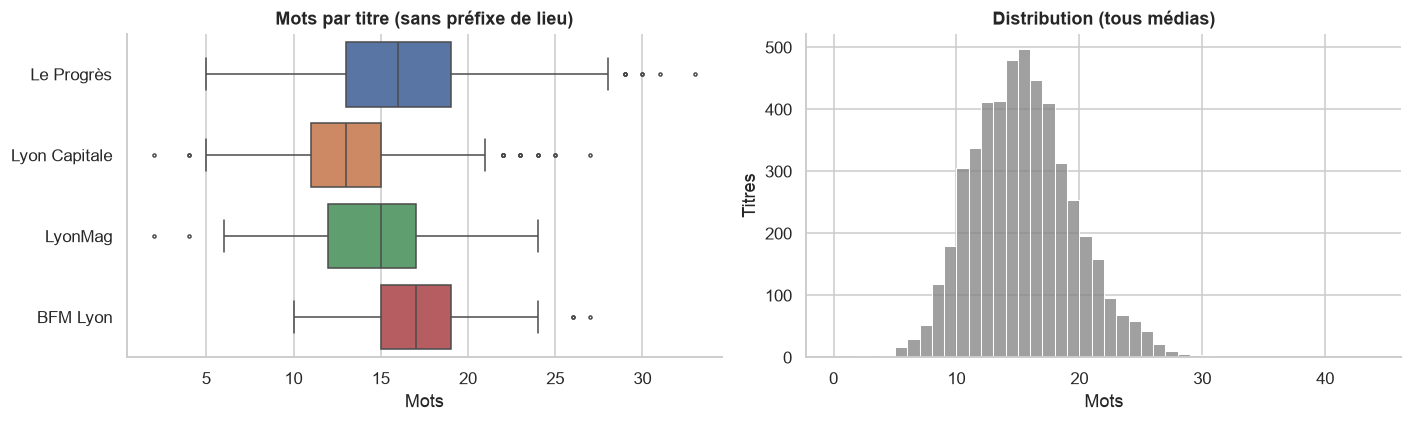

Titres de moins de 5 mots : 5 (0.1%)


,media_name,title
6437,Lyon Capitale,Symphonie messianesque à l'Auditorium
9857,Lyon Capitale,Littérature : Magnifique Zad
10969,Lyon Capitale,Moritz Ostruschnjak
11835,LyonMag,"Grégory Doucet, pitoyable !"
12770,LyonMag,Gilets jaunes


In [8]:
df["n_chars"] = df["title_clean"].str.len(); df["n_words"] = df["title_clean"].str.split().str.len()
stats = df.groupby("media_name")[["n_chars", "n_words"]].describe().round(1).reindex(MEDIA_ORDER)
display(stats.loc[:, [("n_words", "mean"), ("n_words", "50%"), ("n_words", "min"), ("n_words", "max"), ("n_chars", "mean")]])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="n_words", y="media_name", order=MEDIA_ORDER, palette=MEDIA_COLORS, ax=axes[0], fliersize=2); axes[0].set(title="Mots par titre (sans préfixe de lieu)", xlabel="Mots", ylabel="")
sns.histplot(df["n_words"], bins=range(0, 45), ax=axes[1], color="grey"); axes[1].set(title="Distribution (tous médias)", xlabel="Mots", ylabel="Titres")
plt.tight_layout(); fig.savefig(FIG / "03_longueur_titres.png", bbox_inches="tight"); plt.show()
print(f"Titres de moins de 5 mots : {(df.n_words < 5).sum()} ({(df.n_words < 5).mean():.1%})")
display(df[df.n_words < 5][["media_name", "title"]].head(6))

## 6. Valeurs manquantes (corpus d'analyse)

In [9]:
cols = ["title_clean", "date", "section", "place_prefix", "themes", "locations", "persons", "organizations", "socialimage", "tone_avg"]
miss = (df[cols].isna().mean() * 100).round(1).to_frame("% manquant")
miss["% manquant, par média"] = [df.groupby("media_name")[c].apply(lambda s: s.isna().mean() * 100).round(0).reindex(MEDIA_ORDER).to_dict() for c in cols]
display(miss)

,% manquant,"% manquant, par média"
title_clean,0.0,"{'Le Progrès': 0.0, 'Lyon Capitale': 0.0, 'LyonMag': 0.0, 'BFM Lyon': 0.0}"
date,0.0,"{'Le Progrès': 0.0, 'Lyon Capitale': 0.0, 'LyonMag': 0.0, 'BFM Lyon': 0.0}"
section,18.1,"{'Le Progrès': 0.0, 'Lyon Capitale': 0.0, 'LyonMag': 100.0, 'BFM Lyon': 78.0}"
place_prefix,56.1,"{'Le Progrès': 0.0, 'Lyon Capitale': 100.0, 'LyonMag': 100.0, 'BFM Lyon': 100.0}"
themes,4.8,"{'Le Progrès': 3.0, 'Lyon Capitale': 7.0, 'LyonMag': 5.0, 'BFM Lyon': 1.0}"
locations,35.3,"{'Le Progrès': 40.0, 'Lyon Capitale': 29.0, 'LyonMag': 35.0, 'BFM Lyon': 40.0}"
persons,76.3,"{'Le Progrès': 84.0, 'Lyon Capitale': 69.0, 'LyonMag': 74.0, 'BFM Lyon': 63.0}"
organizations,70.8,"{'Le Progrès': 74.0, 'Lyon Capitale': 68.0, 'LyonMag': 68.0, 'BFM Lyon': 77.0}"
socialimage,1.0,"{'Le Progrès': 0.0, 'Lyon Capitale': 2.0, 'LyonMag': 0.0, 'BFM Lyon': 0.0}"
tone_avg,0.0,"{'Le Progrès': 0.0, 'Lyon Capitale': 0.0, 'LyonMag': 0.0, 'BFM Lyon': 0.0}"


## 7. Synthèse de l'étape 3

- **Périmètre analysé** : 4 936 articles (35 % du corpus) : Le Progrès 2 171 (44 %), Lyon Capitale 1 855 (38 %), LyonMag 832 (17 %), BFM Lyon 78 (1,6 %).
- **Volume** : 54 articles/jour en moyenne (de 32 à 75), 310 à 434 par semaine, sans tendance marquée. Août est plus bas (48/jour) que septembre (59) et octobre (55) ; novembre ne compte qu'un jour. Une explication par les vacances est plausible mais non démontrée.
- **Rythme hebdomadaire** : Lyon Capitale publie ≈ 17 % de ses articles chaque jour de semaine mais seulement 8 % le samedi et le dimanche ; Le Progrès et LyonMag sont presque uniformes. Les séries **journalières** ont donc un cycle de 7 jours : l'étape 6 raisonnera à la **semaine**.
- **Titres** : 13 à 17 mots en moyenne selon le média, seulement 0,1 % de moins de 5 mots. Ils portent assez de texte pour du TF-IDF, mais restent courts (peu de mots informatifs après nettoyage).
- **Données écartées ou signalées** : 84 fiches d'agenda et 6 contenus sponsorisés exclus de l'analyse ; 31 articles à titre identique (0,6 %) conservés (rubriques récurrentes comme « Le récap' des temps forts de la semaine »).
- **Jours creux** : Le Progrès les 12 et 13 octobre (11 et 33 articles), plus quelques jours isolés de LyonMag. Conséquence mesurée : la semaine du 12 octobre, Le Progrès ne pèse que 33,5 % du périmètre (44 % en moyenne) et LyonMag 25,6 % (17 % en moyenne). **Un changement de composition par média peut faire croire à une émergence** ; l'étape 6 pondérera donc chaque média par sa part moyenne.
- **Contenu du Progrès** : rubriques dominantes faits-divers-justice (537) et economie (527), puis societe (239) ; territoires Rhône (585), Lyon (492), Métropole de Lyon (437). Les autres médias n'ont pas de rubrique exploitable (Lyon Capitale : 89 % « actualite »). Les rubriques du Progrès serviront de **référence externe** pour juger les clusters à l'étape 5.
- **Valeurs manquantes** : les entités GDELT sont lacunaires (personnes 76 %, organisations 71 %, lieux 35 % manquants) ; on s'appuiera sur le texte des titres.